<a href="https://colab.research.google.com/github/settoseb/assignment_9_network_security/blob/main/Assignment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment #9 - Network Security Aalborg Univeristy


## Can we trust an ML-based network intrusion detector?

**AAU · Fall 2026 · Group lab · 90–120 minutes**

**Goal:** Train a simple NIDS classifier, evaluate it properly, and decide whether you would deploy it in a real SOC. Strong analysis matters more than a high accuracy score.

**How to use:** Open this `.ipynb` in [Google Colab](https://colab.research.google.com/) (**File → Upload notebook**), then run the cells in order. You can also use Jupyter locally with `pandas`, `numpy`, `scikit-learn`, and `matplotlib`.

**Dataset:** UNSW-NB15. The notebook downloads a copy of the **published train/test CSV partitions**, hosted in a public GitHub mirror, and traces them to the [original UNSW dataset](https://research.unsw.edu.au/projects/unsw-nb15-dataset). If the mirror is unavailable, upload the two files yourself from the official source. No malware binaries or live attacks are involved.


### You will answer
1. What are the features and labels? Where could **label leakage** occur?
2. Is high accuracy sufficient when attacks are rare? What do **precision, recall, and FPR** imply for analysts?
3. How does a decision threshold change security outcomes?
4. What happens to alert volume at a hypothetical **1% attack prevalence**?
5. Would you deploy the model? What would you change first?

### 0 · Setup and configuration
Default: the real UNSW-NB15 dataset. Smaller subsets keep training fast in Colab.

In [ ]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)

SEED = 42 # we always try to use a specific seed number to make our experiment reproducible
MAX_TRAIN_ROWS = 50_000  # Increase to None to use all 175,341 training rows
MAX_TEST_ROWS = 20_000   # Increase to None to use all 82,332 testing rows

np.random.seed(SEED)
print("Ready: Python", sys.version.split()[0], "| pandas", pd.__version__)

Ready: Python 3.13.16 | pandas 2.2.3


### 1 · Load the real dataset
`label = 1` means attack, `label = 0` means normal. `attack_cat` is a separate attack-type annotation. **Do not use it as an input feature** for binary attack detection: it contains label information. (what happens if include `attack_cat` as input feature?)

If automatic download fails, the notebook offers a Colab upload step. In local Jupyter, place `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` alongside the notebook.

In [ ]:
TRAIN_URL = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_training-set.csv"
TEST_URL  = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_testing-set.csv"

def load_csv(filename, url):
    from pathlib import Path
    if Path(filename).is_file():
        print('Using local file:', filename)
        return pd.read_csv(filename, low_memory=False)
    try:
        print('Downloading:', filename)
        return pd.read_csv(url, low_memory=False)
    except Exception as exc:
        print('Download error:', type(exc).__name__, str(exc)[:150])
        try:
            from google.colab import files
            print('Please upload:', filename)
            files.upload()
            return pd.read_csv(filename, low_memory=False)
        except ImportError:
            raise RuntimeError('Download failed. Put the official CSV files next to the notebook and rerun.') from exc


train_raw = load_csv('UNSW_NB15_training-set.csv', TRAIN_URL)
test_raw = load_csv('UNSW_NB15_testing-set.csv', TEST_URL)


# Take separate stratified samples of the predefined training and testing partitions.
def take_sample(df, n):
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    part, _ = train_test_split(df, train_size=n, stratify=df['label'], random_state=SEED)
    return part.reset_index(drop=True)

train_df = take_sample(train_raw, MAX_TRAIN_ROWS)
test_df  = take_sample(test_raw, MAX_TEST_ROWS)
print('Training shape:', train_df.shape, '| Test shape:', test_df.shape)
print('Columns:', train_df.columns.tolist())
display(train_df.head(4))

Downloading: UNSW_NB15_training-set.csv
Downloading: UNSW_NB15_testing-set.csv
Training shape: (50000, 45) | Test shape: (20000, 45)
Columns: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,138281,0.312025,tcp,-,FIN,12,8,2918,356,60.892555,...,1,1,0,0,0,1,1,0,Exploits,1
1,34447,0.438444,tcp,-,FIN,28,30,4480,3080,130.005204,...,1,3,0,0,0,3,5,0,Normal,0
2,59065,0.000008,unas,-,INT,2,0,200,0,125000.000300,...,1,5,0,0,0,2,5,0,Reconnaissance,1
3,38417,0.000076,udp,-,INT,2,0,503,0,13157.895320,...,20,20,0,0,0,20,20,0,Normal,0


In [ ]:
print("Train attack fraction:", train_df["label"].mean())
print("Test attack fraction: ", test_df["label"].mean())

Train attack fraction: 0.68062
Test attack fraction:  0.5506


### Investigation A · Understand the data (10–15 minutes)
Run the cells and record your answers in the SLP.

**A1.** Identify three **numeric** and two **categorical** features. Explain what information each might capture about network behavior. (you may want to find more info about the dataset on the internet)

Numerical: there is the 'dpkts' that tracks the number of packets sent from the destination to the source and the 'spkts' columns, which tracks the number of packets sent from the source to the destination. Then there is also the 'dur' which tracks the duration of the connection (from first to last packet).

Categorical:
**attack_cat**, is a categorical feature indicating what type of network traffic it is. For instance we see normal which indicates that its normal traffic but we also see the types of Exploit and Reconnnaissance. **is_ftp_login** is also categorical: a binary flag. Although stored as numbers the value it represents is a label (yes or no), not quantities. This feature captures whether or not and FTP session was accessed with a user name and password.

**A2.** Compare the attack fraction of the training and test data. Would these proportions normally be expected in an organization's network? Why not?

In our training set we can see the fraction is 68.1% attacks and in the test set it is 55.1%. Both sets have a majority of attacks in them, while the test dataset have around 13% fewer then the training.

Train attack fraction: 0.68062
Test attack fraction:  0.5506

These datasets doesn't simulate a real company, because we would expect that the majority of the traffic within a company would contain a much higher margin of benign traffic than attack. The reason the datasets contain a lot of attacks is because its used to train a ML model. If it simulated a real company, the model would likely not be able to classiy attacks as good, since there would be far fewer attacks than benign, and then the model wouldnt learn how to classify attacks from benign.

**A3.** Which columns must be excluded from input features to avoid direct leakage? Can a feature be problematic even if it is not literally called `label`?

In [ ]:
print('Target distribution:')
display(pd.DataFrame({
    'train': train_df['label'].value_counts(normalize=True).sort_index(),
    'test': test_df['label'].value_counts(normalize=True).sort_index()
}).rename(index={0:'Normal (0)',1:'Attack (1)'}).style.format('{:.1%}'))
print('Missing values (top 10):')
display(train_df.isna().sum().sort_values(ascending=False).head(10).to_frame('missing'))
print('Most common attack labels (training):')
display(train_df['attack_cat'].value_counts().head(10).to_frame('rows'))

Target distribution:


,train,test
label,,
Normal (0),31.9%,44.9%
Attack (1),68.1%,55.1%


Missing values (top 10):


,missing
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0


Most common attack labels (training):


,rows
attack_cat,
Normal,15969
Generic,11550
Exploits,9507
Fuzzers,5121
DoS,3424
Reconnaissance,2957
Analysis,558
Backdoor,535
Shellcode,339


### 2 · Feature preparation and training/validation split
- **Official test data remains held out** until the final evaluation. (we are not applying K-Fold in this example)
- We split the **official training partition** into model-fitting and validation sets. Threshold decisions should use validation results, not test results (using test set for this is a common mistake).
- Missing values are filled using **training-only** statistics; categorical features are one-hot encoded. (what is one-hot encoding? learn about it onn the internet)
- `id`, `label`, and `attack_cat` are intentionally excluded. (why do we always remove unique features such as id?)

In [ ]:
TARGET = 'label'
DROP_COLS = ['id', 'label', 'attack_cat']
DROP_EXTRA_FEATURES = []  # if this list is empty all features are included, otherwise we can focus on some feature names as input.

features = [c for c in train_df.columns if c not in DROP_COLS + DROP_EXTRA_FEATURES]
X_all = train_df[features].copy()
y_all = train_df[TARGET].astype(int)
X_test = test_df[features].copy() # remember that the test data is held out from the beginning.
y_test = test_df[TARGET].astype(int)

# now we split the total data (X_all and y_all) to train and validation sets.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_all, y_all, test_size=0.25, random_state=SEED, stratify=y_all)

categorical_features = X_fit.select_dtypes(include=['object','category']).columns.tolist()
numeric_features = [f for f in features if f not in categorical_features]

# what is happening here?
preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])

model = Pipeline([
    ('prepare', preprocess),
    ('classifier', RandomForestClassifier(n_estimators=75, max_depth=14,
        min_samples_leaf=2, random_state=SEED, n_jobs=-1))
])
print('Training model on', len(X_fit), 'flows with', len(features), 'raw input features…')
model.fit(X_fit, y_fit)
val_prob = model.predict_proba(X_val)[:,1]
print('Done. Validation rows:', len(X_val))

Training model on 37500 flows with 42 raw input features…
Done. Validation rows: 12500


### 3 · Evaluate a baseline (15 minutes)
A classifier that always predicts the most frequent class is a simple baseline. Compare that baseline with the trained Random Forest. (sometimes our baseline is a model from another paper becasue we want to build a better model than other models)

**B1.** Report **accuracy, precision, recall, F1, and false-positive rate**. Which metric matters most for an analyst, and why?

**B2.** Interpret the confusion matrix in words: which error can cause an undetected attack, and which error consumes analyst time?

**B3.** Does a high result on this validation set guarantee performance on future traffic? Give two reasons.

,threshold,TP,FP,TN,FN,accuracy,precision,recall (TPR),FPR,F1
Always-majority baseline,0.5,8508,3992,0,0,0.6806,0.6806,1.0000,1.0000,0.8100
Random Forest,0.5,8394,528,3464,114,0.9486,0.9408,0.9866,0.1323,0.9632


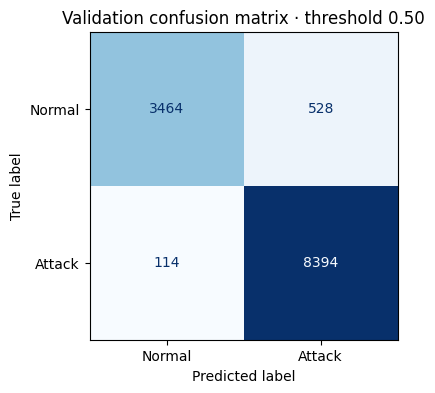

In [ ]:
def metrics_at_threshold(y_true, probabilities, threshold=0.5):
    pred = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {'threshold':threshold, 'TP':int(tp), 'FP':int(fp), 'TN':int(tn), 'FN':int(fn),
            'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall (TPR)': recall_score(y_true, pred, zero_division=0),
            'FPR': fp/(fp+tn) if (fp+tn) else 0.0,
            'F1': f1_score(y_true, pred, zero_division=0)}

baseline = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_fit),1)), y_fit) # this is our baseline - but it can be a competetor model from another researcher
base_pred = baseline.predict(np.zeros((len(y_val),1)))
base_stats = metrics_at_threshold(y_val, base_pred)
rf_stats = metrics_at_threshold(y_val, val_prob)
display(pd.DataFrame([base_stats,rf_stats], index=['Always-majority baseline','Random Forest']).round(4))

fig, ax = plt.subplots(figsize=(5,4))
# let's use .5 as the threshold - meaning that output greater equal than .5 shows a positive (malicious) output
ConfusionMatrixDisplay.from_predictions(y_val, val_prob >= .5,
    display_labels=['Normal','Attack'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Validation confusion matrix · threshold 0.50')
plt.show()

### 4 · Adjust the threshold without touching the test set (20 minutes)
Most classifiers return a probability or score. An alert is raised when the score exceeds a chosen threshold.

**C1.** Which threshold would you use if false alerts are costly? Which if missed attacks are most costly? Explain the trade-off, **using your table**.

**C2.** Select a threshold and justify it in 2–4 sentences. Do **not** tune the threshold against the test set later.


,threshold,TP,FP,FN,precision,recall (TPR),FPR,F1
0,0.10,8508,834,0,0.9107,1.0000,0.2089,0.9533
1,0.20,8507,818,1,0.9123,0.9999,0.2049,0.9541
2,0.35,8502,776,6,0.9164,0.9993,0.1944,0.9560
3,0.50,8394,528,114,0.9408,0.9866,0.1323,0.9632
4,0.65,8086,268,422,0.9679,0.9504,0.0671,0.9591
5,0.80,7709,105,799,0.9866,0.9061,0.0263,0.9446
6,0.90,7054,14,1454,0.9980,0.8291,0.0035,0.9058
7,0.95,6551,3,1957,0.9995,0.7700,0.0008,0.8699


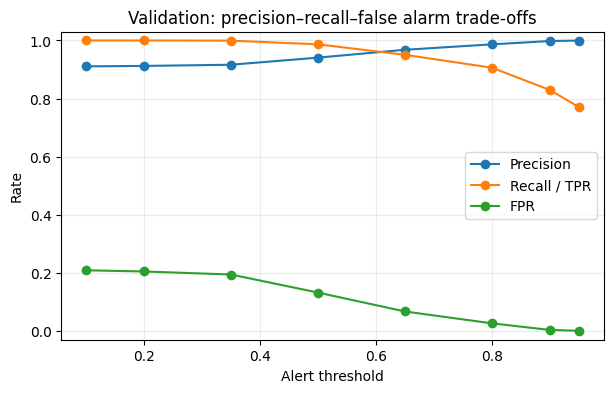

Chosen validation threshold: 0.5
Validation at chosen threshold: {'threshold': 0.5, 'TP': 8394, 'FP': 528, 'TN': 3464, 'FN': 114, 'accuracy': 0.94864, 'precision': 0.9408204438466712, 'recall (TPR)': 0.9866008462623413, 'FPR': np.float64(0.13226452905811623), 'F1': 0.9631669535283993}


In [ ]:
thresholds = [0.10, 0.20, 0.35, 0.50, 0.65, 0.80, 0.90, 0.95] # we want to test the performance for differnet thresholds to find best in our project
valid_table = pd.DataFrame([metrics_at_threshold(y_val, val_prob, t) for t in thresholds])
display(valid_table[['threshold','TP','FP','FN','precision','recall (TPR)','FPR','F1']].round(4))
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(valid_table['threshold'], valid_table['precision'], marker='o', label='Precision')
ax.plot(valid_table['threshold'], valid_table['recall (TPR)'], marker='o', label='Recall / TPR')
ax.plot(valid_table['threshold'], valid_table['FPR'], marker='o', label='FPR')
ax.set(xlabel='Alert threshold',ylabel='Rate',ylim=(-0.03,1.03),title='Validation: precision–recall–false alarm trade-offs')
ax.grid(alpha=.25)
ax.legend()
plt.show()

CHOSEN_THRESHOLD = 0.50  # please change this value based on validation table and justify in the SLP.
print('Chosen validation threshold:', CHOSEN_THRESHOLD)
print('Validation at chosen threshold:', metrics_at_threshold(y_val,val_prob,CHOSEN_THRESHOLD))

### 5 · The **base-rate problem**: from test metrics to SOC operations (20 minutes)
A research dataset may contain many attacks. In a production network the attack fraction could be much smaller. **Suppose, hypothetically, that 1% (p) of 100,000 (N) daily flows are malicious.**



If TPR and FPR transferred unchanged to that environment (a *strong assumption*), then

$$
TP = N \times p \times TPR
$$

$$
FN = N \times p \times (1-TPR)
$$

$$
FP = N \times (1-p) \times FPR
$$

$$
TN = N \times (1-p) \times (1-FPR)
$$

$$
\text{Expected Precision} = \frac{TP}{TP+FP}
$$

**D1.** How many alerts per day would the detector generate? How many alerts would be false? What fraction of alerts would be genuine?

**D2.** Suppose an analyst spends **3 minutes investigating each alert**. How many analyst-hours per day would be required if *every* alert needs investigation? Is this feasible? State simplifying assumptions.

**D3.** Explain why the precision calculated on the research test set may differ from the estimated precision in a real network. What other differences besides prevalence might invalidate this projection?

In [ ]:
def project_soc(tpr, fpr, daily_flows=100_000, attack_prevalence=.01, minutes_per_alert=3):
    malicious = daily_flows * attack_prevalence
    benign = daily_flows - malicious
    tp, fn = malicious*tpr, malicious*(1-tpr)
    fp, tn = benign*fpr, benign*(1-fpr)
    alerts = tp + fp
    return dict(daily_flows=daily_flows, prevalence=attack_prevalence,
        expected_TP=tp, expected_FP=fp, expected_FN=fn, expected_TN=tn,
        expected_alerts=alerts, expected_precision=tp/alerts if alerts else 0.0,
        analyst_hours=alerts*minutes_per_alert/60)

hypotheses = []
for t in [0.20, 0.50, 0.80, CHOSEN_THRESHOLD]: # chosen threshold comes from the previous cell
    m = metrics_at_threshold(y_val, val_prob, t)
    forecast = project_soc(m['recall (TPR)'], m['FPR'])
    hypotheses.append({'threshold':t, **forecast})
display(pd.DataFrame(hypotheses).drop_duplicates('threshold').round(2))

# Challenge: change prevalence from 1% to 0.1% and compare expected precision.
print('At 0.1% prevalence, chosen threshold:')
m = metrics_at_threshold(y_val, val_prob, CHOSEN_THRESHOLD)
display(pd.DataFrame([project_soc(m['recall (TPR)'],m['FPR'],attack_prevalence=.001)]).round(2))

,threshold,daily_flows,prevalence,expected_TP,expected_FP,expected_FN,expected_TN,expected_alerts,expected_precision,analyst_hours
0,0.2,100000,0.01,999.88,20286.07,0.12,78713.93,21285.95,0.05,1064.30
1,0.5,100000,0.01,986.60,13094.19,13.40,85905.81,14080.79,0.07,704.04
2,0.8,100000,0.01,906.09,2603.96,93.91,96396.04,3510.05,0.26,175.50


At 0.1% prevalence, chosen threshold:


,daily_flows,prevalence,expected_TP,expected_FP,expected_FN,expected_TN,expected_alerts,expected_precision,analyst_hours
0,100000,0.0,98.66,13213.23,1.34,86686.77,13311.89,0.01,665.59


### 6 · Final evaluation on the untouched test partition (10–15 minutes)
**Freeze your threshold before executing this cell.** The goal is to observe how well your chosen procedure generalizes to a different held-out partition.

**E1.** Compare validation with test results. Is one better? Why might the two results differ? Do not claim causality without evidence.

**E2.** Inspect the false negatives and false positives by attack category. Which attacks would remain a concern?

,threshold,TP,FP,TN,FN,accuracy,precision,recall (TPR),FPR,F1
Validation,0.5,8394,528,3464,114,0.9486,0.9408,0.9866,0.1323,0.9632
Held-out test,0.5,10943,2939,6049,69,0.8496,0.7883,0.9937,0.3270,0.8792


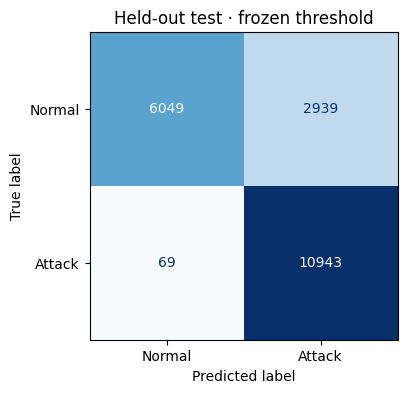

,flows,attacks,missed_attacks,miss_rate_for_attacks
attack_cat,,,,
Generic,4617,4617,0,0.000
Exploits,2663,2663,2,0.001
Fuzzers,1468,1468,65,0.044
DoS,1023,1023,0,0.000
Reconnaissance,835,835,1,0.001
Analysis,173,173,0,0.000
Backdoor,132,132,0,0.000
Shellcode,92,92,1,0.011
Worms,9,9,0,0.000


In [ ]:
test_prob = model.predict_proba(X_test)[:,1]
test_stats = metrics_at_threshold(y_test, test_prob, CHOSEN_THRESHOLD)
val_stats = metrics_at_threshold(y_val, val_prob, CHOSEN_THRESHOLD)
display(pd.DataFrame([val_stats,test_stats], index=['Validation','Held-out test']).round(4))

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prob >= CHOSEN_THRESHOLD,
    display_labels=['Normal','Attack'], cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Held-out test · frozen threshold')
plt.show()

inspect = test_df[['attack_cat','label']].copy()
inspect['predicted_attack'] = (test_prob >= CHOSEN_THRESHOLD).astype(int)
inspect['missed_attack'] = ((inspect['label']==1)&(inspect['predicted_attack']==0))
by_cat = inspect.groupby('attack_cat').agg(flows=('label','size'),
    attacks=('label','sum'), missed_attacks=('missed_attack','sum'))
by_cat['miss_rate_for_attacks'] = by_cat['missed_attacks']/by_cat['attacks'].replace(0,np.nan)
display(by_cat.sort_values('attacks', ascending=False).round(3))



**Dataset attribution:** N. Moustafa and J. Slay, *UNSW-NB15: a comprehensive data set for network intrusion detection systems*, MilCIS (2015); [UNSW project page](https://research.unsw.edu.au/projects/unsw-nb15-dataset). This lab uses published train/test partitions and (by default) stratified subsets for speed. It does not reproduce the original paper's experiments.